-   1.开场三问
    -   1.1上次组会后我卡在哪个问题上？
        -   郭老师和尹老师提出：两个问题：
            -   1.1.1 在重建中，重建图像有明显的伪影去除，但是在真实人体组织中，如何区分去除的伪影部分不会是真实组织呢?
            -   1.1.2 在重建中，出现明显的亮点丢失的原因是什么？
            -   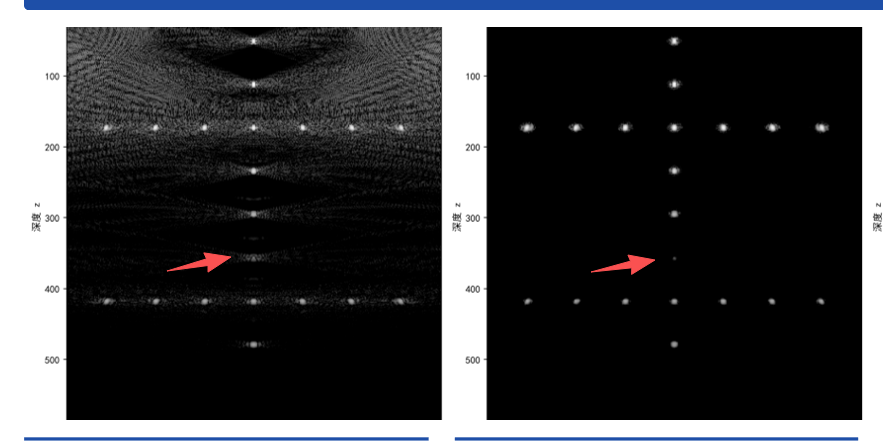如图，红色箭头指向明显变淡，甚至丢失
            -   直接对应到第 2 块的 H1 假设——即「在已知真点的 phantom 上，用点目标恢复率 ≥1 + 消声区 CNR 上升」来证明。你的图正好是 H1/H2 的「证据素材」。
    -   1.2今天这堆活，在整条链（数据→模型→训练→指标→评价→部署）上覆盖了哪几环？
        -   今天要解决导师提出的两个问题，主要是在评价阶段；总体来说覆盖了数据（PICMUS数据和data）模型（mdels—UNet）训练（train）指标（metrics）评价（伪影VS真实组织）
    -   1.3今天做完，我能多做哪一件具体的事？
        -   明天我能用今天写好的 CNR/gCNR/点目标恢复率/FWHM，把 11/9 的重建结果量化成一张「保组织 vs 抗伪影」的表，而不是继续用眼睛判断「亮点看起来丢了」。

-   2.3个可证伪假设
    -   H1：如何证明删掉的是伪影儿不是真实组织
        -   如果重建只删除伪影、保留真实组织，那么在已知真点的phantom上：
            -   重建后点目标恢复率：DL峰值/高质峰值≥1（真组织没被削弱，甚至更强）
            -   消声区（本应无回声的区域，也就是背景纯黑的部分）的CNR（对比噪声比）=（目标区均值-背景区均值）/背景区标准差（噪声） 上升（伪影减少，背景更加干净）我用PICMUS/自仿真的已知真点+消声区来测试
        -   判伪证据:
            -   若点目标恢复率＜1，或者消声区CNR不升反降，则H1不成立
    -   H2：亮点为什么丢失（假设过平滑）
        -   如果亮点丢失根本原因是过平滑（回归均值抹平稀疏强点），那么就换残差学习+强点/边缘加权损失后，点目标恢复率明显回升
        -   我对比baseline vs 改进模型的点目标恢复率
        -   判伪证据：
            -   若加残差+加权损失后点目标恢复率无明显回升（比如提升 < 某阈值），则 H2 不成立——亮点丢失不是（主要）由过平滑导致。
    -   H3：亮点为什么丢失（假设归一化/动态范围）
        -   如果亮点丢失根本原因是db压缩+归一化截断强点峰值有关，那么训练前归一化会将强点峰值压平/截断
        -   我检查归一化前后强点的相对幅度变化
        -   判伪证据：
            -   若归一化前后强点的相对幅度几乎不变，则H3不成立

-   3.复现亮点丢失
    -   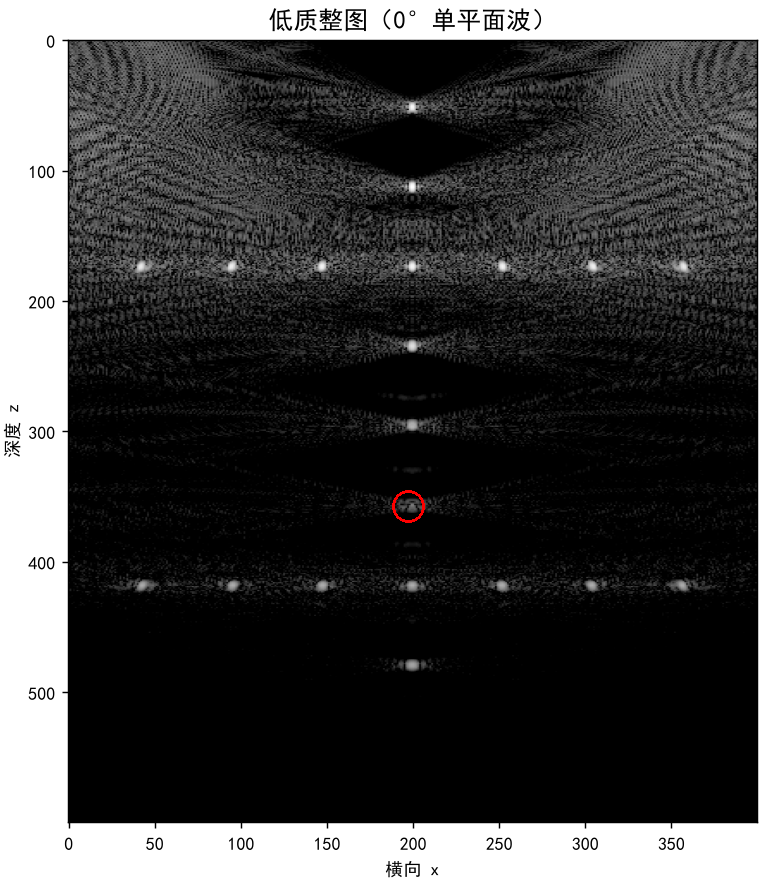
    -   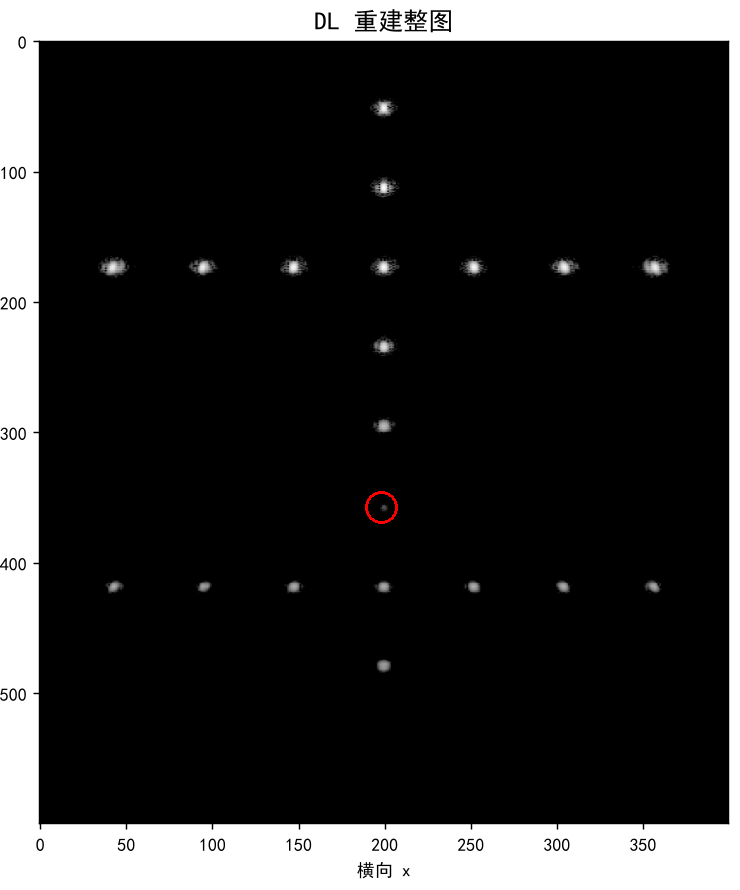
    -   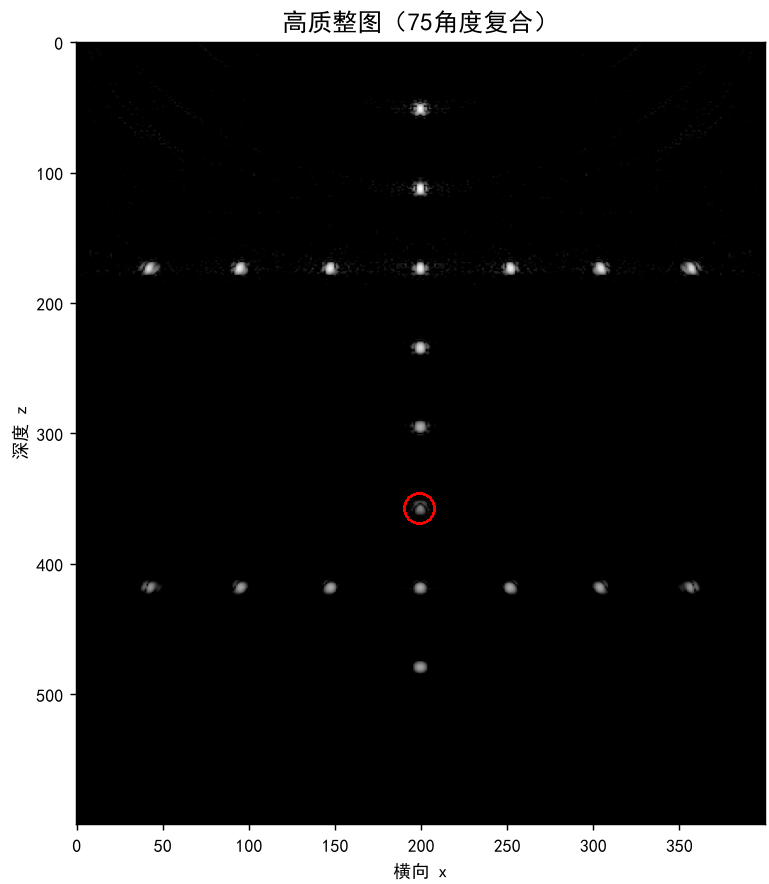
    -   图像中，低质图，有信号，被旁瓣噪声包围，重建后被抑制变暗，说明网络可能将真点+周围旁瓣 一同当做伪影去掉

-   4.repo骨架
    -   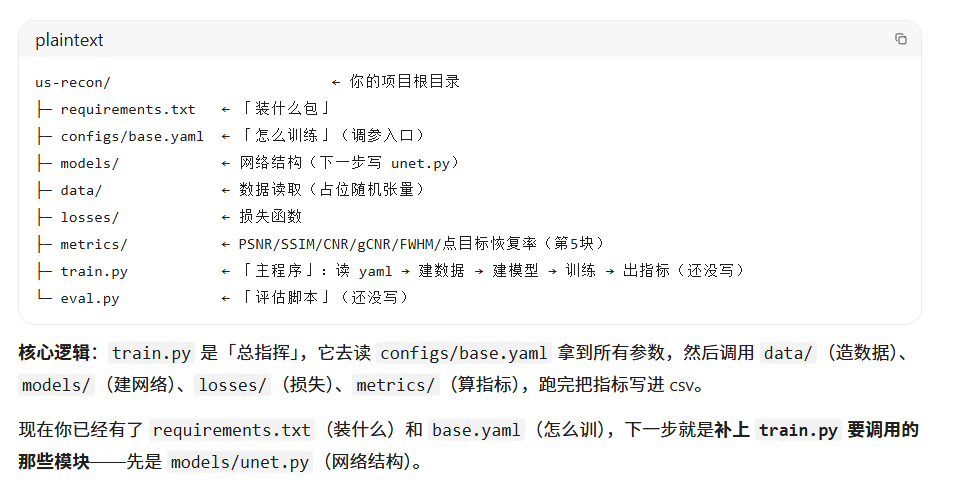
    -   细节：
        -   requirements.txt——依赖清单（装什么包）
            -   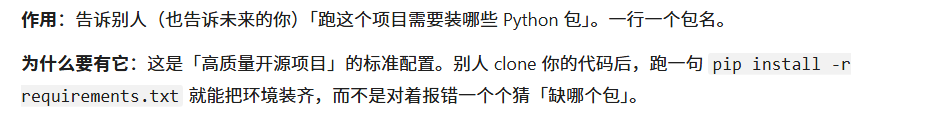
            -   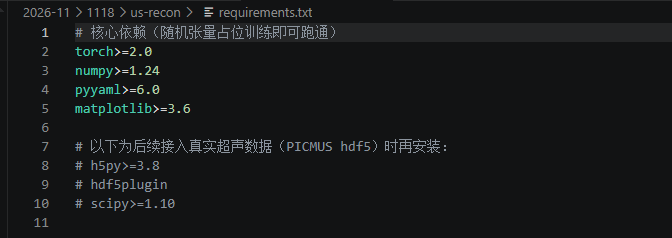
                -   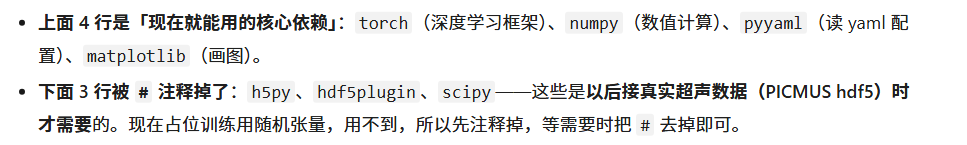
        -   configs/base.yaml(训练配置——调参不用碰代码)
            -   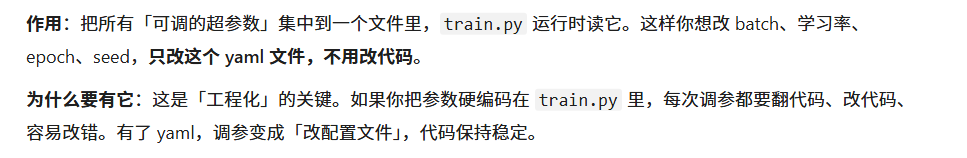
            -   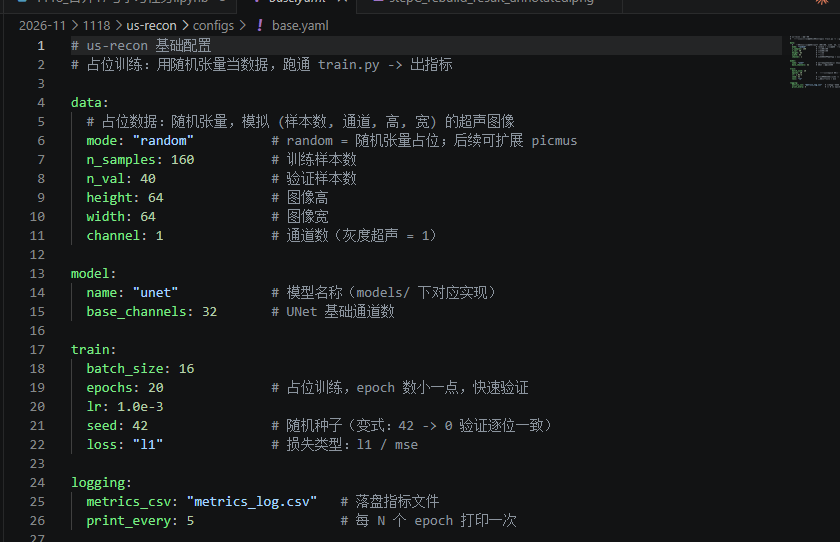

-   4.repo骨架
    -   medels/UNet
    -   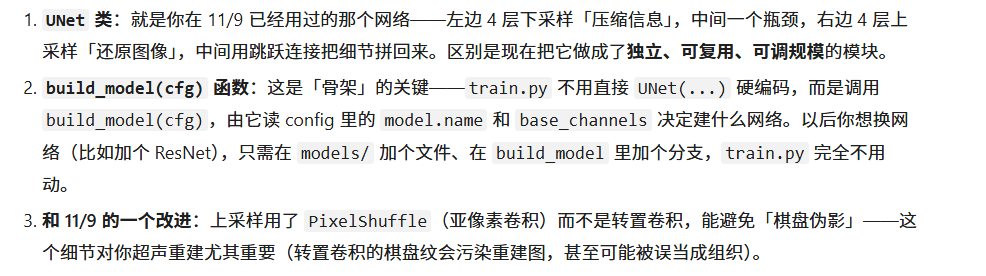

In [ ]:
# -*- coding: utf-8 -*-
"""
UNet 网络定义（超声重建用）
结构：编码器(4层下采样) -> 瓶颈 -> 解码器(4层上采样，PixelShuffle)
上采样采用 PixelShuffle（亚像素卷积），避免转置卷积的棋盘伪影。
"""
import torch
import torch.nn as nn
    

class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base=32):
        super().__init__()
        self.enc1 = self._block(in_ch, base)
        self.pool = nn.MaxPool2d(2)

        self.enc2 = self._block(base, base * 2)
        self.enc3 = self._block(base * 2, base * 4)
        self.enc4 = self._block(base * 4, base * 8)
        self.bottleneck = self._block(base * 8, base * 16)

        self.up4 = nn.Sequential(nn.Conv2d(base * 16, base * 8 * 4, 1), nn.PixelShuffle(2))
        self.dec4 = self._block(base * 16, base * 8)

        self.up3 = nn.Sequential(nn.Conv2d(base * 8, base * 4 * 4, 1), nn.PixelShuffle(2))
        self.dec3 = self._block(base * 8, base * 4)

        self.up2 = nn.Sequential(nn.Conv2d(base * 4, base * 2 * 4, 1), nn.PixelShuffle(2))
        self.dec2 = self._block(base * 4, base * 2)

        self.up1 = nn.Sequential(nn.Conv2d(base * 2, base * 4, 1), nn.PixelShuffle(2))
        self.dec1 = self._block(base * 2, base)

        self.out = nn.Conv2d(base, out_ch, 1)

    def _block(self, in_c, out_c):
        return nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.out(d1)


def build_model(cfg):
    name = cfg["model"]["name"]
    if name == "unet":
        return UNet(
            in_ch=cfg["data"]["channel"],
            out_ch=cfg["data"]["channel"],
            base=cfg["model"]["base_channels"],
        )
    raise ValueError(f"未知模型名称: {name}")


-   4.repo骨架
    -   data/
        -   如果要接入新的数据则需要更改哪些：
            -   新增一个PicmusDataset类（不是改现有的RandomPairDataset）
                -   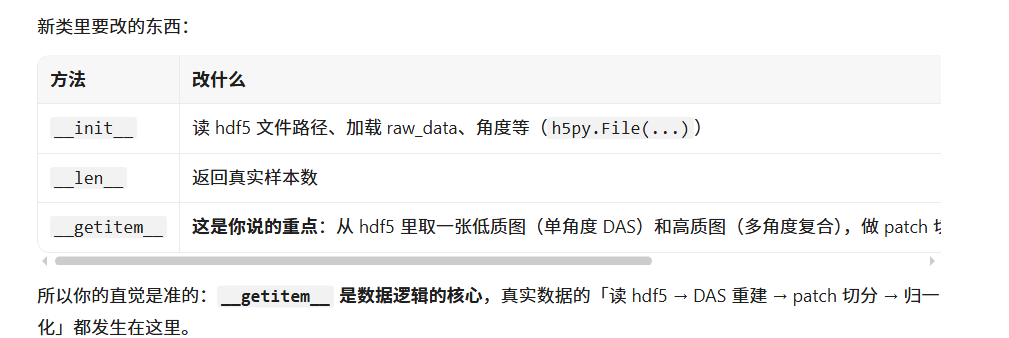
            -   改build_dataloader(cfg,seed)里的if分支
                -   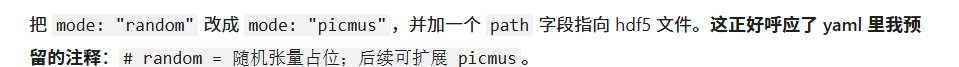
            -   改cofigs/base.yaml中的data.mode
                -   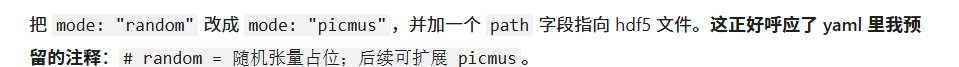
        -   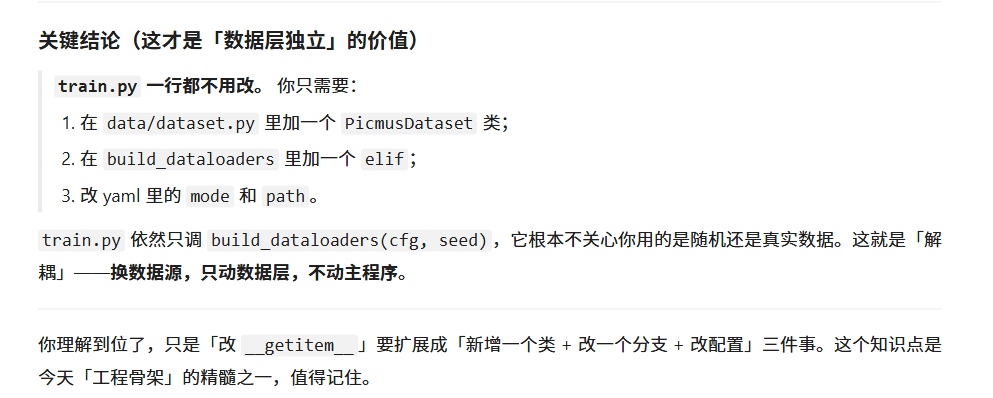

-   4.repo骨架
    -   losses
        -   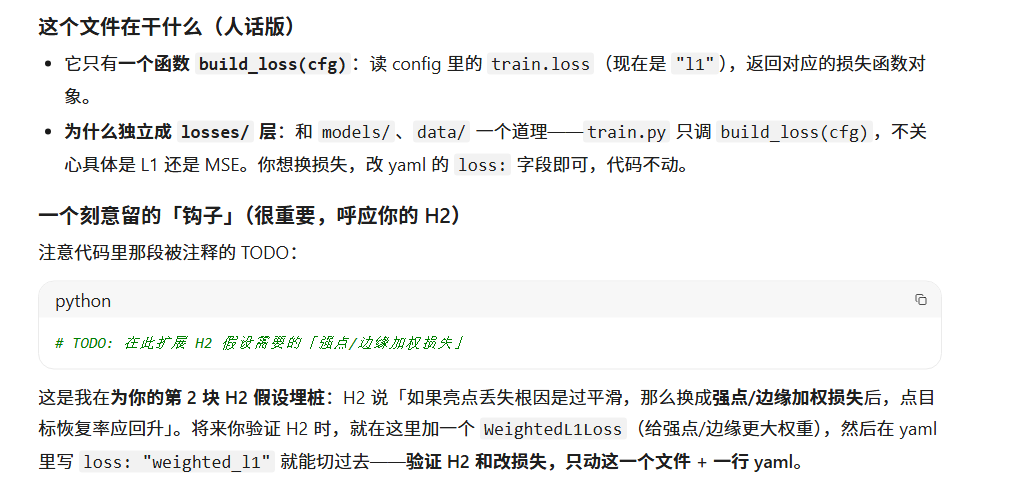

-   4.repo骨架
    -   metrics &train.py
        -  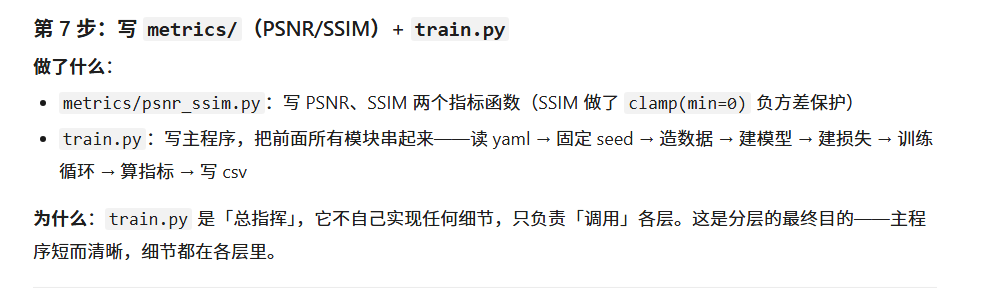 

-   4.repo骨架
    -   seed是什么
        -   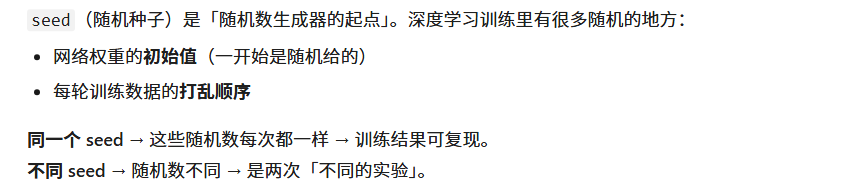
        -   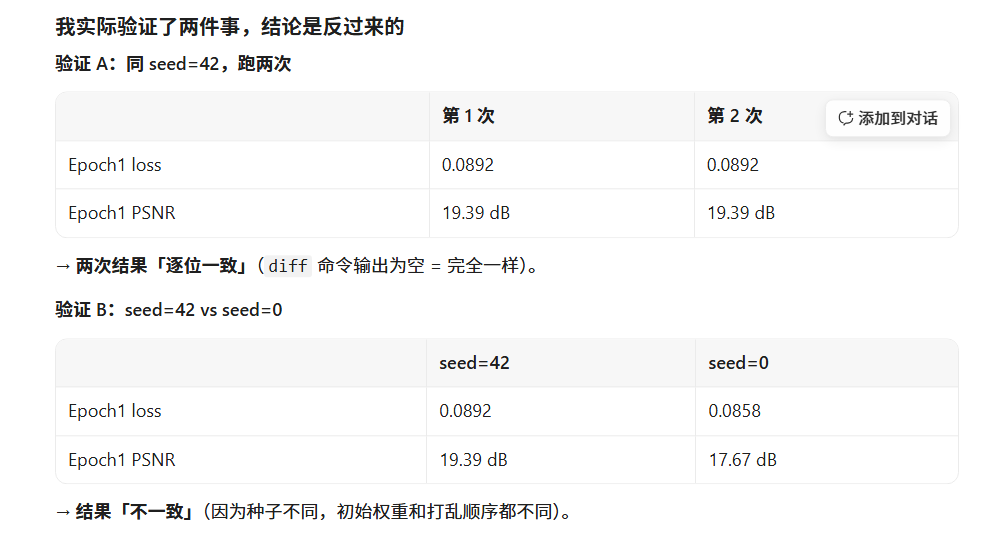

-   5.指标函数
    -   cnr：对比噪声度
        -   CNR=（目标区像素均值-背景区像素均值）/背景区像素标准差（噪声/伪影水平）
        -   含义
            -   衡量目标区相对背景有多突出。伪影多→背景像素标准差大→CNR低
            -   如果伪影被清除→背景变干净→背景区像素标准差→CNR上升
    -   gcnr：广义对比噪声度
        -   cnr的默认背景是高斯分布，但是真实的超声的伪影，分布不是高斯分布。所以gcnr不假设任何分布形状，直接比两个分布直方图重叠
    -   FWHM:半高全宽
        -   剖面：穿过一个点散射体画一条线，得到一维信号——中间高，两边低
        -   一个理想点散射体，重建出来应该是一个很窄的尖峰。如果重建把它「抹糊」了（过平滑），峰就会变宽，FWHM 变大。所以：
    -   点目标恢复率
        -   DL峰值/高质峰值
        -   =1，这个点被保住了，＞1则说明增强了这个点
        -   ＜1，说明这个点被削弱了，正是亮点丢失的量化
    -   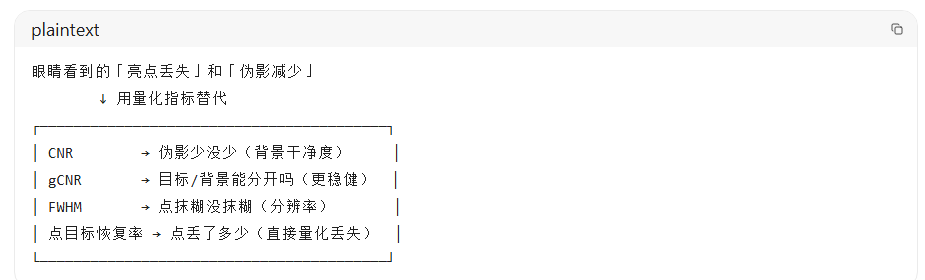


-   6.伪影三兄弟
    -   1.栅瓣：因为超声阵元的间距不够密集，除了主波束之外，别的角度也同样出现了强的假波束。相当于一个假的主瓣
        -   图中：出现偏离真实位置的假亮点
    -   2.旁瓣：任何一个波束，都不是一根正中间的针一样，而是中间的主瓣最强，两边还拖着几圈越来越弱的边，是天生的，主瓣两边的小突起，无法完全消除
        -   图中：一个点散射体周围拖出几卷暗影
    -   3.混响：超声波在强反射体之间来回反弹，
        -   图中：在深度方向上一串等距的重复亮点
    -   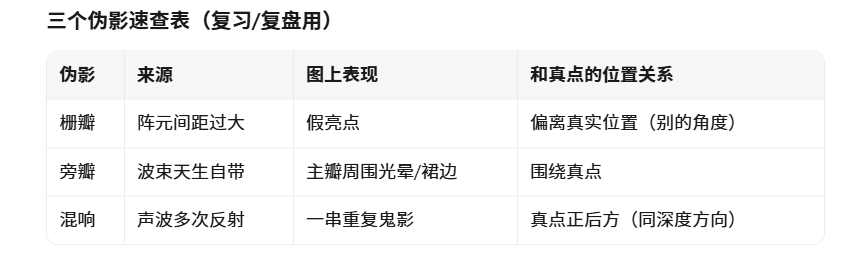

-   7.论文
    -   标题：Physics-Guided Multi-Objective Deep Learning for Ultrasound RF Data Interpolation in Resource-Constrained Imaging
        -   基于物理引导的多目标深度学习用于资源受限成像中的超声射频数据插值
    -   Abstract：
        -   Ultrasound imaging increasingly targets portable, point-of-care, and wearable settings where constraints on power, bandwidth, and hardware complexity often necessitate sparse data acquisition in spatiotemporal scanning.
            -   超声成像越来越多地应用于便携式、床边护理和可穿戴设备场景，这些场景中由于电源、带宽和硬件复杂度的限制，往往需要在时空扫描中采集稀疏数据。
        -   However, image reconstruction using the sparse data can introduce insufficient phase information in coherent beamforming process, resulting in grating-lobe artifacts that degrade imaging contrast resolution.
            -   然而，使用稀疏数据进行图像重建可能会在相干波束成形过程中引入不足的相位信息，从而产生光栅状伪影，降低成像的对比度分辨率。
        -   We present a physics-guided, data-driven framework for sparse-to-dense radio-frequency (RF) reconstruction that aligns training with downstream image formation.
            -   我们提出了一种基于物理引导、数据驱动的稀疏到密集射频（RF）重建框架，使训练与下游图像生成相匹配。
        -   Our approach trains an end-to-end interpolation network using a hybrid supervision scheme that combines an RF-domain and a beamforming-domain loss with exponential moving average (EMA) to stabilize the multi-objective training.
            -   我们的方法采用混合监督方案，结合射频域和波束成形域的损失函数，并使用指数加权移动平均（EMA）来稳定多目标训练，从而训练一个端到端的插值网络。
        -   To improve generalization under variable acquisition layouts, we also introduce a random-skip masking strategy that varies sparsity patterns during training so a single model can handle diverse decimation factors and irregular channel configurations.
            -   为了在变化的采集布局下提升泛化能力，我们还引入了一种随机跳过掩码策略，在训练过程中动态调整稀疏模式，使单一模型能够应对不同的降采样因子和不规则的通道配置。
        -   We evaluate the framework on a held-out test set using the mean structural similarity index measure (SSIM) between reconstructed and ground-truth beamformed images.
            -   我们使用重建图像与真实波束成形图像之间的平均结构相似性指数（SSIM）来评估该框架在预留测试集上的表现。
        -   Across decimation factors ×2 to ×13, the bestperforming configuration maintains mean SSIM around 0.95.
            -   在从×2到×13的多种衰减因子下，性能最佳的配置保持了平均SSIM约为0.95。
        -   Overall, the results show consistent gains in RF reconstruction and post-beamforming image quality across diverse acquisition conditions.
            -   总体而言，结果表明在各种采集条件下，射频重建和后束成像质量均表现出持续的提升。
        -   This approach enables robust, high-quality ultrasound imaging at resource-constrained settings by allowing more sparse scanning in spatiotemporal domain.
            -   这种方法通过在时空间域中实现更稀疏的扫描，使资源受限环境下的超声成像更加稳健且高质量。
        -   摘要总结：
            -   针对稀疏采样会出现栅瓣伪影，提出一种基于物理引导、数据驱动的框架。采用混合监督结合射频域和波束形成域的损失函数联合训练出端到端的网络。重建后平均SSIM值稳定在~0.95
    -   Conclusion：
        -   We develop a new physics-guided framework for reconstructing dense ultrasound RF data from sparse acquisitions.
            -   我们开发了一种基于物理的新型框架，用于从稀疏采集数据中重建密集的超声射频数据。
        -   By coupling an RF-domain reconstruction objective with a beamforming-domain objective through a differentiable beamformer, the proposed method aligns RF interpolation with downstream image formation and improves artifact suppression under coherent DAS.
            -   通过将射频域重建目标与可微分波束成形器结合的波束成形域目标，该方法实现了射频插值与下游图像生成的一致性，并在相干分布式阵列（DAS）下提升了伪影抑制能力。
        -   To stabilize optimization across varying sampling conditions, we further introduced EMA-based adaptive loss balancing and random-skip masking during training to improve robustness to diverse decimation patterns.
            -   为了在不同的采样条件下稳定优化，我们进一步在训练过程中引入基于EMA的自适应损失平衡和随机跳过掩码，以增强对不同降采样模式的鲁棒性。
        -   Experiments on simulated data showed that these components provide complementary benefits when combined.
            -   对模拟数据的实验表明，这些组件在结合使用时能提供互补的优势。
        -   In particular, the best-performing configuration, which combines beamforming-guided supervision, EMA-based weighting, random-skip training, and a hybrid convolution–attention backbone, maintained mean SSIM near 0.95 across decimation factors from ×2 to ×13.
            -   特别是，性能最佳的配置结合了波束成形引导的监督、基于EMA的权重、随机跳过训练以及混合卷积-注意力骨干网络，在降采样因子从×2到×13的范围内，均保持了接近0.95的平均SSIM值。
        -   These results indicate strong robustness under severe undersampling and encouraging generalization beyond the sparsity range seen during training.
            -   这些结果表明，在严重欠采样情况下具有很强的鲁棒性，并且在训练过程中观察到的稀疏范围之外仍表现出良好的泛化能力。
    -   启发：作者在训练的过程中将物理一致性beamforming和射频域直接嵌入损失函数。这很好的呼应了我的假设一[如何证明去掉的不是真实组织而是伪影]：不是靠纯数据驱动区猜，而是用物理约束保证取掉的是伪影，留下的是真实组织。明确提出了，稀疏采集→栅瓣伪影是头号敌人